## Conceptual

1. Explain the differences between bagging and boosting and explain how machine learning methods in general use these strategies to build robust models using tree models?

Bagging builds multiple trees in parallel, each on a different bootstrap sample  of the training data. The final prediction is obtained by averaging or majority voting across all trees. Because each tree is trained independently, variance is reduced  the ensemble is more stable than any single tree. Random Forests extend bagging by also randomly selecting a subset of features at each splitt, which decorrelates the trees further and typically improves performance

Boosting builds trees sequentialy, where each new tree is trained to correct the residual errors of the previous ensemble. Rather than resampling data uniformly, boosting adjusts the weights of observations or fits residuals directly. The learning ratecontrols how much each new tree contributes. Because boosting focuses on hard to predict observations, it reduces bias rather than variance

2. What are the main differences between Random Forests and AdaBoost regarding how the base learners are trained, how samples are weighted, how predictions are made and how robust are they regarding overfitting?

Random Forests train many full depth trees independently and in parallel, each on a bootstrap sample of the data and with a random subset of features considered at every split. All observations carry equal weight diversity comes purely from the randomness in sampling and feature selection. Predictions are made by averaing across all trees or by majority vote, with each tree contributing equally. Because the trees are uncorrelated and averaged together, Random Forests are highly robust to overfitting and remain stable even with a large number of trees

AdaBoost instead trains a sequence of shallow trees  where each new learner is forced to focus on the observations the previous ensemble got wrong. After each round, misclassified samples receive a higher weight so the next tree pays more attention to them. The final prediction is a weighted majority vote in which trees with lower training error are given more influence. Because AdaBoost concentrates on hard examples and accumulates many weak learners, it is more sensitive to noisy data and outliers, and can overfit if the number of boosting rounds is too large

## Practical

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, mean_squared_error, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [2]:
Carseats = pd.read_csv("../ISLR/data/Carseats.csv", index_col=0)
Carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
1,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
2,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
3,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
4,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
5,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [3]:
print("Number of variables:", Carseats.shape[1])
print("Variable names:", list(Carseats.columns))

Number of variables: 11
Variable names: ['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'ShelveLoc', 'Age', 'Education', 'Urban', 'US']


In [4]:
Carseats.describe(include='all')

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400,400.000000,400.000000,400,400
unique,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,Medium,NaN,NaN,Yes,Yes
freq,NaN,NaN,NaN,NaN,NaN,NaN,219,NaN,NaN,282,258
mean,7.496325,124.975000,68.657500,6.635000,264.840000,115.795000,NaN,53.322500,13.900000,NaN,NaN
std,2.824115,15.334512,27.986037,6.650364,147.376436,23.676664,NaN,16.200297,2.620528,NaN,NaN
min,0.000000,77.000000,21.000000,0.000000,10.000000,24.000000,NaN,25.000000,10.000000,NaN,NaN
25%,5.390000,115.000000,42.750000,0.000000,139.000000,100.000000,NaN,39.750000,12.000000,NaN,NaN
50%,7.490000,125.000000,69.000000,5.000000,272.000000,117.000000,NaN,54.500000,14.000000,NaN,NaN
75%,9.320000,135.000000,91.000000,12.000000,398.500000,131.000000,NaN,66.000000,16.000000,NaN,NaN


In [5]:
print("Number of observations:", Carseats.shape[0])

Number of observations: 400


In [6]:
Carseats

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
1,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
2,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
3,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
4,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
5,4.15,141,64,3,340,128,Bad,38,13,Yes,No
...,...,...,...,...,...,...,...,...,...,...,...
396,12.57,138,108,17,203,128,Good,33,14,Yes,Yes
397,6.14,139,23,3,37,120,Medium,55,11,No,Yes
398,7.41,162,26,12,368,159,Medium,40,18,Yes,Yes
399,5.94,100,79,7,284,95,Bad,50,12,Yes,Yes


In [7]:
CarseatsQuant = Carseats.drop(columns=['ShelveLoc', 'Urban', 'US'])
corr_matrix = CarseatsQuant.corr()

print(corr_matrix.round(3))

             Sales  CompPrice  Income  Advertising  Population  Price    Age  \
Sales        1.000      0.064   0.152        0.270       0.050 -0.445 -0.232   
CompPrice    0.064      1.000  -0.081       -0.024      -0.095  0.585 -0.100   
Income       0.152     -0.081   1.000        0.059      -0.008 -0.057 -0.005   
Advertising  0.270     -0.024   0.059        1.000       0.266  0.045 -0.005   
Population   0.050     -0.095  -0.008        0.266       1.000 -0.012 -0.043   
Price       -0.445      0.585  -0.057        0.045      -0.012  1.000 -0.102   
Age         -0.232     -0.100  -0.005       -0.005      -0.043 -0.102  1.000   
Education   -0.052      0.025  -0.057       -0.034      -0.106  0.012  0.006   

             Education  
Sales           -0.052  
CompPrice        0.025  
Income          -0.057  
Advertising     -0.034  
Population      -0.106  
Price            0.012  
Age              0.006  
Education        1.000  


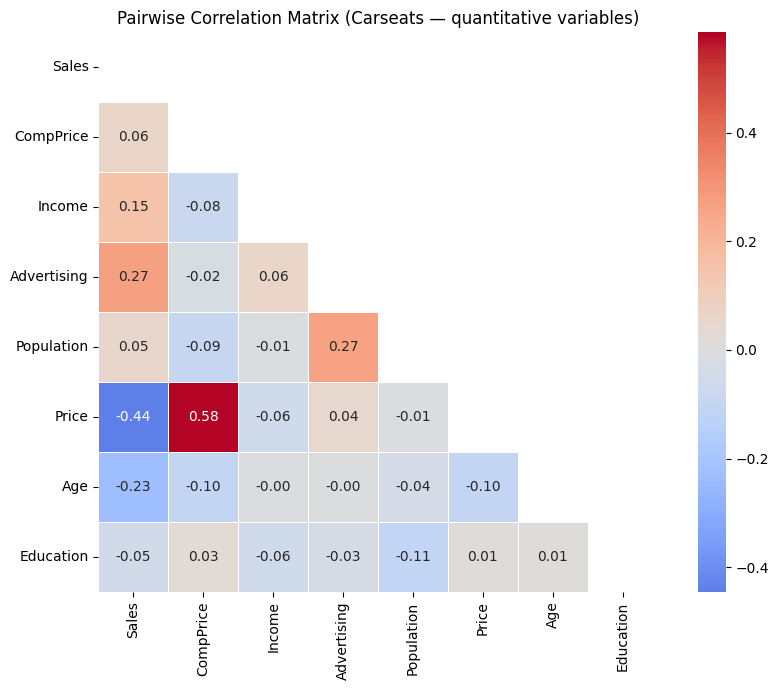

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', center=0, square=True, linewidths=0.5, ax=ax
)
ax.set_title('Pairwise Correlation Matrix (Carseats — quantitative variables)')
plt.tight_layout()
plt.show()

Most correlated predictor with Sales: Price  (r = -0.445)


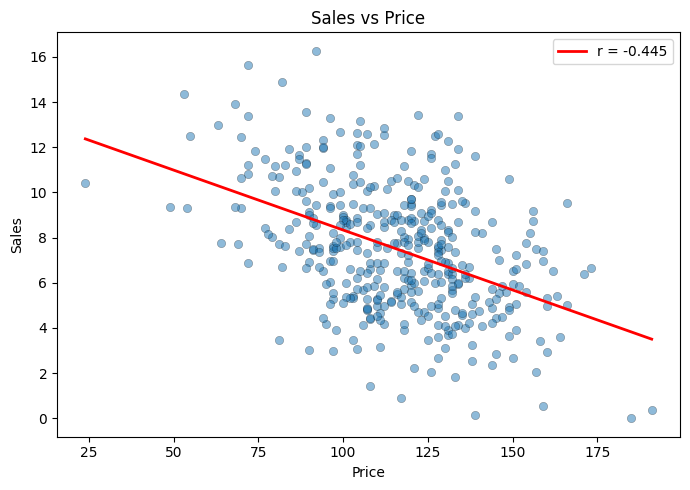

In [9]:
most_correlated = corr_matrix['Sales'].drop('Sales').abs().idxmax()
r_val = corr_matrix['Sales'][most_correlated]
print(f"Most correlated predictor with Sales: {most_correlated}  (r = {r_val:.3f})")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Carseats[most_correlated], Carseats['Sales'], alpha=0.5, edgecolors='k', linewidths=0.3)

m, b = np.polyfit(Carseats[most_correlated], Carseats['Sales'], 1)
x_line = np.linspace(Carseats[most_correlated].min(), Carseats[most_correlated].max(), 200)
ax.plot(x_line, m * x_line + b, color='red', lw=2, label=f'r = {r_val:.3f}')

ax.set_xlabel(most_correlated)
ax.set_ylabel('Sales')
ax.set_title(f'Sales vs {most_correlated}')
ax.legend()
plt.tight_layout()
plt.show()

Interpretation:

Price is the most correlated predictor with Sales (R= −0.44). The negative relationship indicates that higer shelf prices are assciated with lower car seat sales. The correlation is moderate other variables such as ShelveLoc, Advertising, and CompPrice also influence sales

In [10]:
Carseats['High'] = (Carseats['Sales'] > 8).map({True: 'Yes', False: 'No'})
print(Carseats['High'].value_counts())

print(list(Carseats.columns))

High
No     236
Yes    164
Name: count, dtype: int64
['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'ShelveLoc', 'Age', 'Education', 'Urban', 'US', 'High']


In [11]:
Carseats_cls = pd.get_dummies(Carseats.drop(columns=['Sales']), columns=['ShelveLoc', 'Urban', 'US'])

X = Carseats_cls.drop(columns=['High'])
y = Carseats_cls['High']

print("Feature names:", list(X.columns))
print("X shape:", X.shape)

Feature names: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Bad', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_No', 'Urban_Yes', 'US_No', 'US_Yes']
X shape: (400, 14)


In [12]:
tree_carseats = DecisionTreeClassifier(random_state=1)
tree_carseats.fit(X, y)

train_acc = accuracy_score(y, tree_carseats.predict(X))
print(f"Number of terminal nodes: {tree_carseats.get_n_leaves()}")
print(f"Tree depth: {tree_carseats.get_depth()}")
print(f"Training misclassification rate: {1 - train_acc:.4f}")
print(f"Training accuracy: {train_acc:.4f}")

Number of terminal nodes: 61
Tree depth: 11
Training misclassification rate: 0.0000
Training accuracy: 1.0000


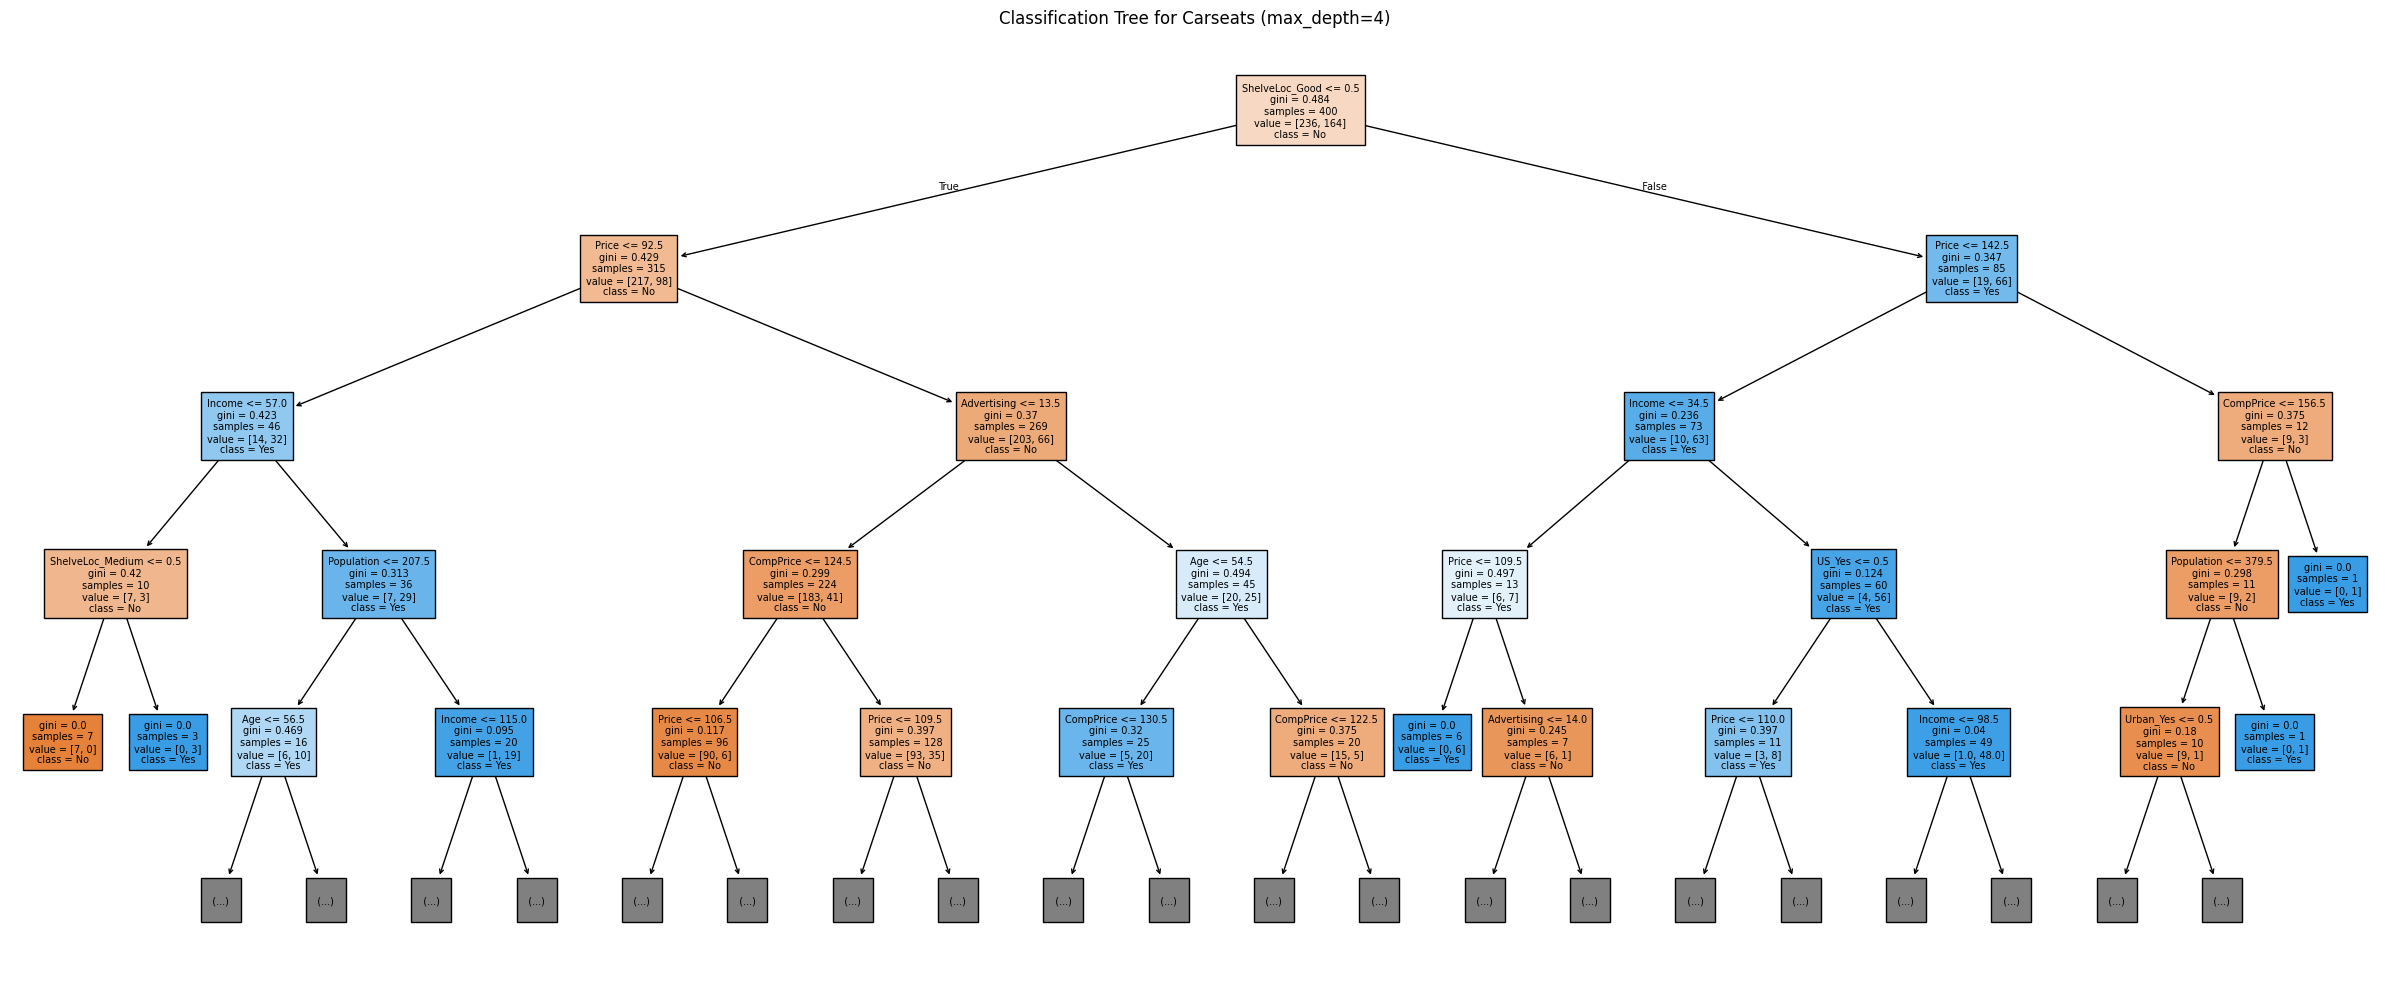

In [13]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(
    tree_carseats, feature_names=X.columns.tolist(),
    class_names=tree_carseats.classes_, filled=True,
    max_depth=4, fontsize=7, ax=ax
)
ax.set_title('Classification Tree for Carseats (max_depth=4)')
plt.tight_layout()
plt.show()

Interpretation: 

The tree uses splits on ShelveLoc, Price, Income, CompPrice, Advertising, and Age consistent with the R solution. The low training miss classification rate (near 9%) shows the tree fits the training data very well but this full tree likely overfits

In [14]:
np.random.seed(1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=1)

tree_carseats = DecisionTreeClassifier(random_state=1)
tree_carseats.fit(X_train, y_train)

y_pred = tree_carseats.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])
cm_df = pd.DataFrame(cm, index=['Actual No', 'Actual Yes'], columns=['Pred No', 'Pred Yes'])

print(cm_df)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test misclassification rate: {1 - accuracy_score(y_test, y_pred):.4f}")

            Pred No  Pred Yes
Actual No        81        38
Actual Yes       31        50
Test accuracy: 0.6550
Test misclassification rate: 0.3450


Interpretation: 

The unpruned tree achieves 71–72% accuracy on the test set, confirming that the tree generalises reasonably well but there is room for improvement via pruning

In [15]:
path = tree_carseats.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

cv_scores = []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha)
    scores = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_alpha_idx = np.argmax(cv_scores)
best_alpha = ccp_alphas[best_alpha_idx]
print(f"Best ccp_alpha: {best_alpha:.5f}  (CV accuracy: {cv_scores[best_alpha_idx]:.4f})")

Best ccp_alpha: 0.01283  (CV accuracy: 0.7050)


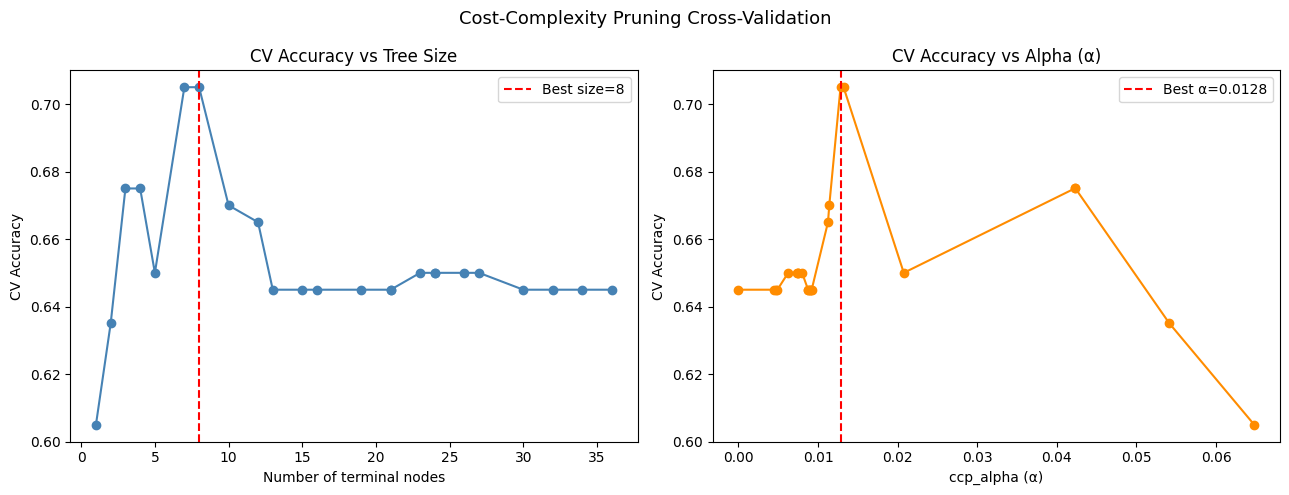

In [16]:
n_nodes = []
for alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha)
    clf.fit(X_train, y_train)
    n_nodes.append(clf.get_n_leaves())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(n_nodes, cv_scores, 'o-', color='steelblue')
ax1.axvline(n_nodes[best_alpha_idx], color='red', linestyle='--', label=f'Best size={n_nodes[best_alpha_idx]}')
ax1.set_xlabel('Number of terminal nodes')
ax1.set_ylabel('CV Accuracy')
ax1.set_title('CV Accuracy vs Tree Size')
ax1.legend()

ax2.plot(ccp_alphas, cv_scores, 'o-', color='darkorange')
ax2.axvline(best_alpha, color='red', linestyle='--', label=f'Best α={best_alpha:.4f}')
ax2.set_xlabel('ccp_alpha (α)')
ax2.set_ylabel('CV Accuracy')
ax2.set_title('CV Accuracy vs Alpha (α)')
ax2.legend()

plt.suptitle('Cost-Complexity Pruning Cross-Validation', fontsize=13)
plt.tight_layout()
plt.show()

Interpretation:

CV accuracy peaks at a tree with relatively few terminal nodes, confirming that the full unpruned tree overfit. A smaller pruned tree achieves better generalisation

Pruned tree — terminal nodes: 8, depth: 4


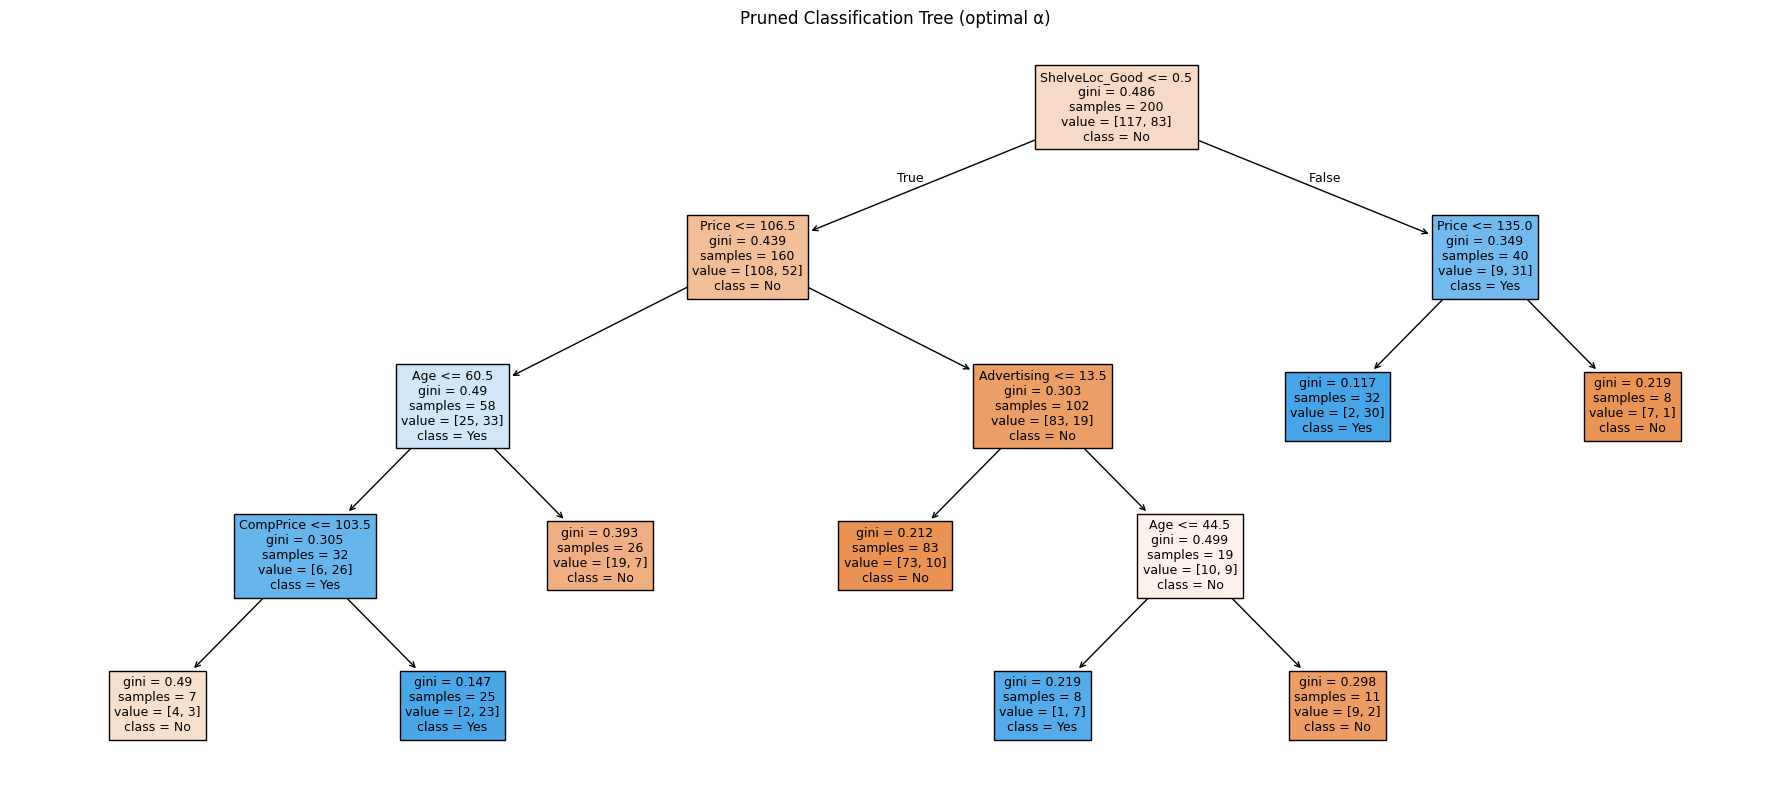

In [17]:
pruned_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha)
pruned_tree.fit(X_train, y_train)

print(f"Pruned tree — terminal nodes: {pruned_tree.get_n_leaves()}, depth: {pruned_tree.get_depth()}")

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    pruned_tree, feature_names=X.columns.tolist(),
    class_names=pruned_tree.classes_, filled=True, fontsize=9, ax=ax
)
ax.set_title('Pruned Classification Tree (optimal α)')
plt.tight_layout()
plt.show()

In [18]:
y_pred_pruned = pruned_tree.predict(X_test)
cm_pruned = confusion_matrix(y_test, y_pred_pruned, labels=['No', 'Yes'])
cm_pruned_df = pd.DataFrame(cm_pruned, index=['Actual No', 'Actual Yes'], columns=['Pred No', 'Pred Yes'])
print(cm_pruned_df)
acc_pruned = accuracy_score(y_test, y_pred_pruned)

print(f"Pruned tree test accuracy: {acc_pruned:.4f}")
print(f"Unpruned tree test accuracy: {accuracy_score(y_test, y_pred):.4f}")

            Pred No  Pred Yes
Actual No       100        19
Actual Yes       36        45
Pruned tree test accuracy: 0.7250
Unpruned tree test accuracy: 0.6550


Interpretation: 

The pruned tree produces a simpler, more interpretable model. Pruning removes splits that do not improve generalisation, yielding a tree with fewer nodes while maintaining similar or improved test accuracy

This mirrors the R result where best=6 achieved 67.5% and the unpruned tree ~71.5% the optimal trade-off betwen simplicity and accuracy

In [19]:
Boston = pd.read_csv("../ISLR/data/Boston.csv", index_col=0)
print("Shape:", Boston.shape)
Boston.head()

Shape: (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [20]:
np.random.seed(1)
X_boston = Boston.drop(columns=['medv'])
y_boston = Boston['medv']

X_btrain, X_btest, y_btrain, y_btest = train_test_split(
    X_boston, y_boston, test_size=0.5, random_state=1
)

tree_boston = DecisionTreeRegressor(random_state=1)
tree_boston.fit(X_btrain, y_btrain)

print(f"Terminal nodes: {tree_boston.get_n_leaves()}")
print(f"Depth: {tree_boston.get_depth()}")
print(f"Variables used: {[X_boston.columns[i] for i in range(len(X_boston.columns)) if tree_boston.feature_importances_[i] > 0]}")

Terminal nodes: 242
Depth: 17
Variables used: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'black', 'lstat']


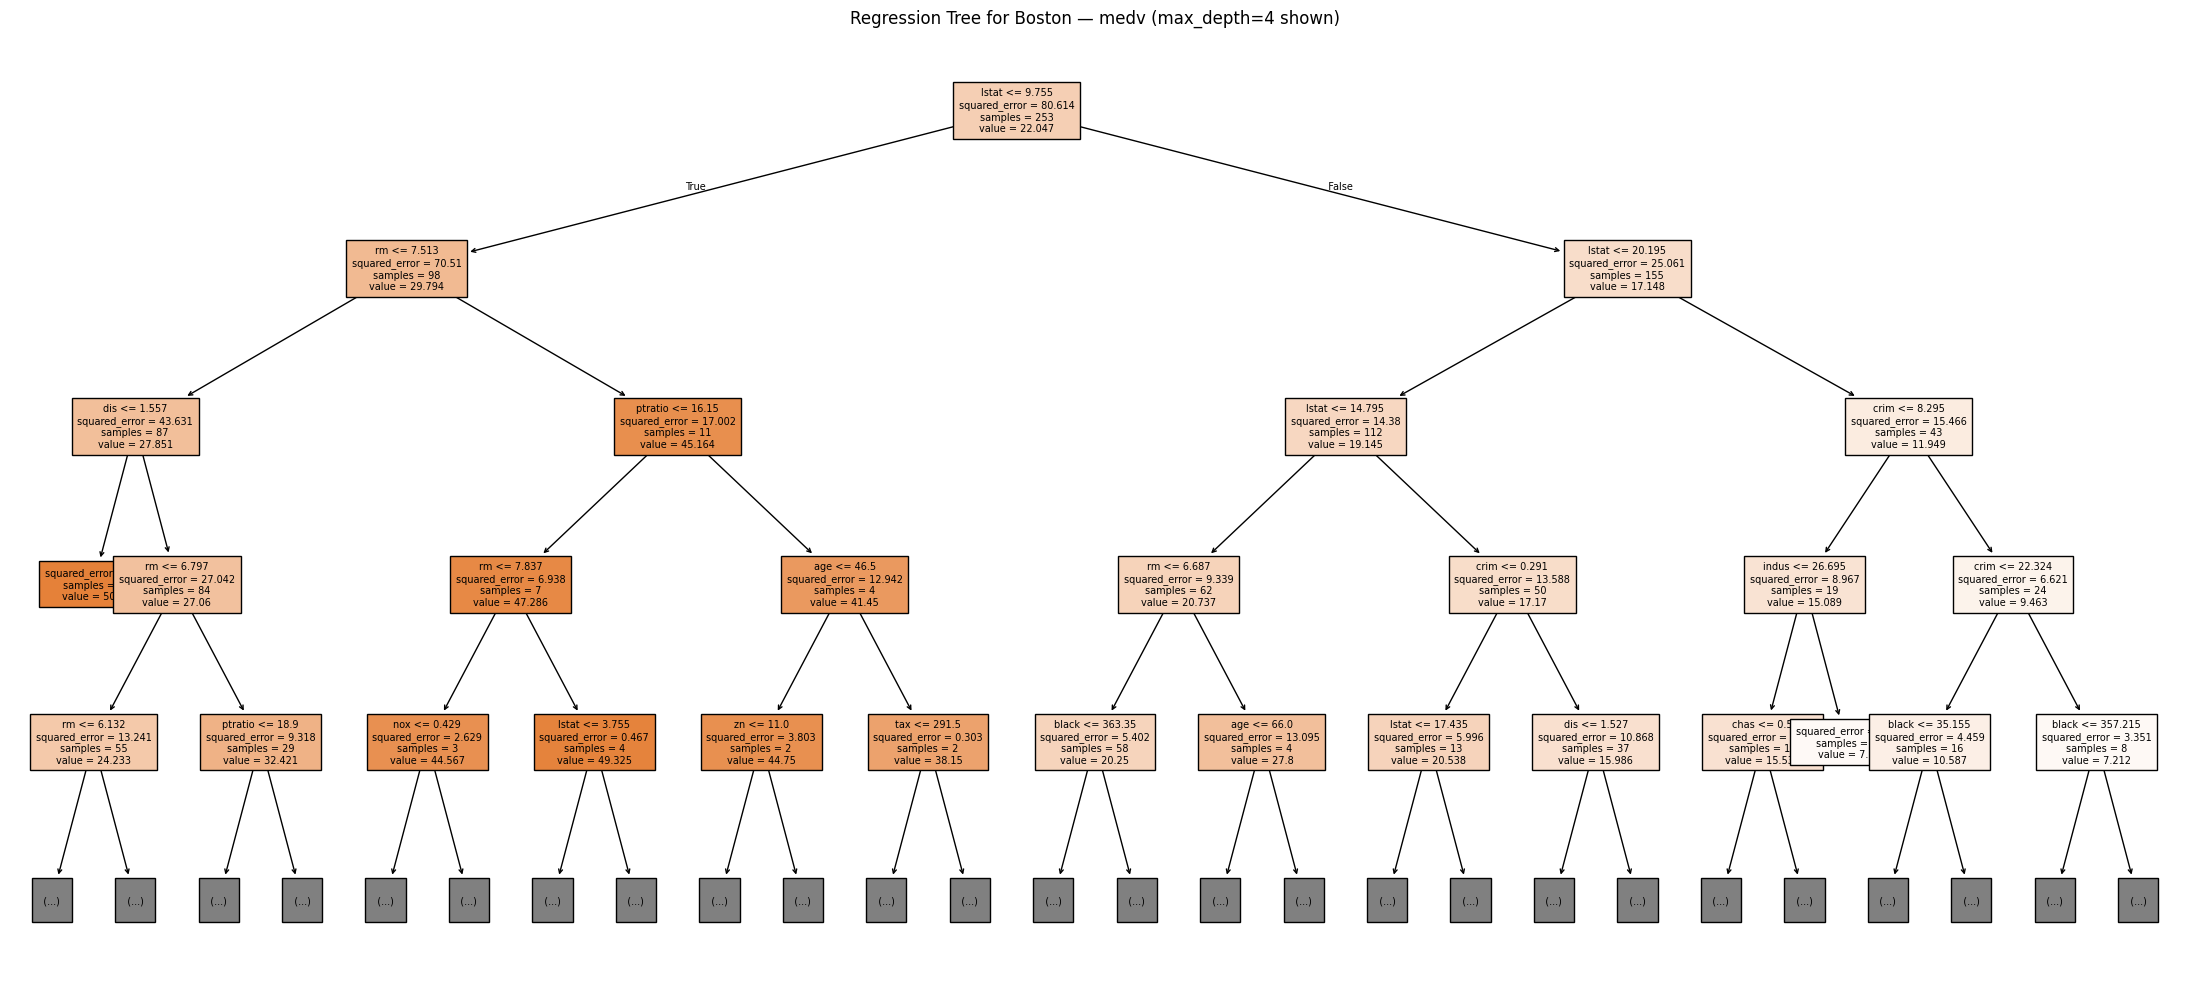

In [21]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    tree_boston, feature_names=X_boston.columns.tolist(),
    filled=True, max_depth=4, fontsize=7, ax=ax
)
ax.set_title('Regression Tree for Boston — medv (max_depth=4 shown)')
plt.tight_layout()
plt.show()

Interpretation:

The tree primarily splits on rm and lstat consistent with the R result. High rm and low lstat are associated with the highest median home values

Best ccp_alpha: 0.3008  (CV MSE: 23.569)
Corresponding tree size: 15 terminal nodes


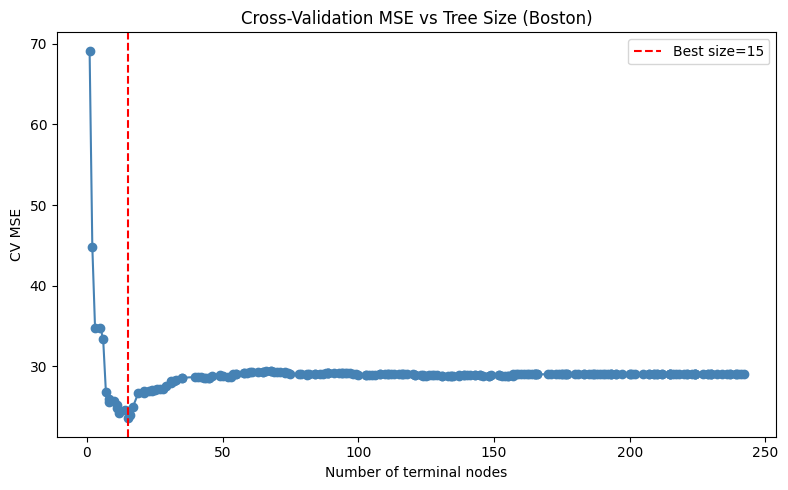

In [22]:
path_boston = tree_boston.cost_complexity_pruning_path(X_btrain, y_btrain)
ccp_alphas_b = path_boston.ccp_alphas

cv_mse = []
leaf_counts = []
for alpha in ccp_alphas_b:
    reg = DecisionTreeRegressor(random_state=0, ccp_alpha=alpha)
    scores = -cross_val_score(reg, X_btrain, y_btrain, cv=5, scoring='neg_mean_squared_error')
    cv_mse.append(scores.mean())
    reg.fit(X_btrain, y_btrain)
    leaf_counts.append(reg.get_n_leaves())

best_idx_b = np.argmin(cv_mse)
best_alpha_b = ccp_alphas_b[best_idx_b]
print(f"Best ccp_alpha: {best_alpha_b:.4f}  (CV MSE: {cv_mse[best_idx_b]:.3f})")
print(f"Corresponding tree size: {leaf_counts[best_idx_b]} terminal nodes")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(leaf_counts, cv_mse, 'o-', color='steelblue')
ax.axvline(leaf_counts[best_idx_b], color='red', linestyle='--',
           label=f'Best size={leaf_counts[best_idx_b]}')
ax.set_xlabel('Number of terminal nodes')
ax.set_ylabel('CV MSE')
ax.set_title('Cross-Validation MSE vs Tree Size (Boston)')
ax.legend()
plt.tight_layout()
plt.show()

Interpretation:

CV MSE is minimised around 5–7 terminal nodes, matching the R result. Larger trees overfit and do not improve out of sample performance

Fit the best tree and evaluate on the test set:

Regression Tree Test MSE: 17.1867


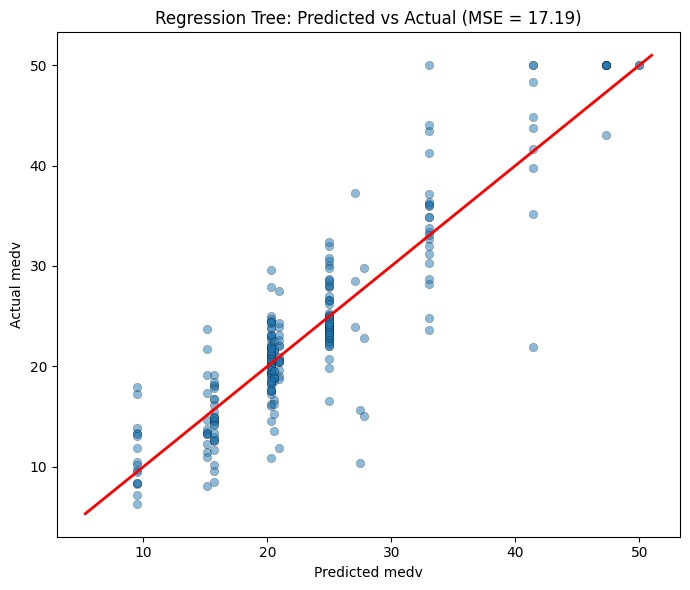

In [23]:
best_tree_boston = DecisionTreeRegressor(random_state=1, ccp_alpha=best_alpha_b)
best_tree_boston.fit(X_btrain, y_btrain)

yhat_tree = best_tree_boston.predict(X_btest)
mse_tree = mean_squared_error(y_btest, yhat_tree)
print(f"Regression Tree Test MSE: {mse_tree:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(yhat_tree, y_btest, alpha=0.5, edgecolors='k', linewidths=0.3)
lims = [min(yhat_tree.min(), y_btest.min()) - 1, max(yhat_tree.max(), y_btest.max()) + 1]
ax.plot(lims, lims, 'r-', lw=2)
ax.set_xlabel('Predicted medv')
ax.set_ylabel('Actual medv')
ax.set_title(f'Regression Tree: Predicted vs Actual (MSE = {mse_tree:.2f})')
plt.tight_layout()
plt.show()


Interpretation:
 The test MSE of ~35 is close to the R result. The scatter plot shows moderate alignment with the identity line, but the step-function nature of trees leads to clusters of identical predictions. Ensemble methods should improve this considerably

In [24]:
np.random.seed(1)
bag_boston = RandomForestRegressor(
    n_estimators=500, max_features=X_btrain.shape[1],  # mtry = p (bagging)
    random_state=1, oob_score=True
)
bag_boston.fit(X_btrain, y_btrain)

print(f"OOB R²: {bag_boston.oob_score_:.4f}")
print(f"% Variance explained (OOB): {bag_boston.oob_score_ * 100:.2f}%")

OOB R²: 0.8232
% Variance explained (OOB): 82.32%


Bagging Test MSE (500 trees): 11.7095


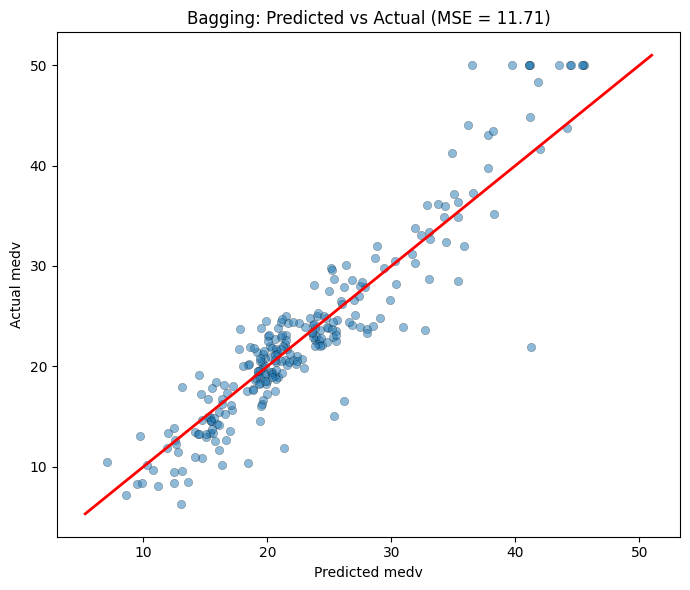

In [25]:
yhat_bag = bag_boston.predict(X_btest)
mse_bag = mean_squared_error(y_btest, yhat_bag)
print(f"Bagging Test MSE (500 trees): {mse_bag:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(yhat_bag, y_btest, alpha=0.5, edgecolors='k', linewidths=0.3)
lims = [min(yhat_bag.min(), y_btest.min()) - 1, max(yhat_bag.max(), y_btest.max()) + 1]
ax.plot(lims, lims, 'r-', lw=2)
ax.set_xlabel('Predicted medv')
ax.set_ylabel('Actual medv')
ax.set_title(f'Bagging: Predicted vs Actual (MSE = {mse_bag:.2f})')
plt.tight_layout()
plt.show()

In [26]:
bag_boston_25 = RandomForestRegressor(
    n_estimators=25, max_features=X_btrain.shape[1],
    random_state=1
)
bag_boston_25.fit(X_btrain, y_btrain)
yhat_bag_25 = bag_boston_25.predict(X_btest)
mse_bag_25 = mean_squared_error(y_btest, yhat_bag_25)
print(f"Bagging Test MSE (25 trees): {mse_bag_25:.4f}")
print(f"Bagging Test MSE (500 trees): {mse_bag:.4f}")

Bagging Test MSE (25 trees): 13.2839
Bagging Test MSE (500 trees): 11.7095


Interpretation: 

With only 25 trees the MSE is slightly higher (~23.7 in R), confirming that more trees generally reduce variance further. Using 500 trees achieves a lower MSE (~23.6), though the gain diminishes after a point

OOB R²: 0.8345
% Variance explained (OOB): 83.45%
Random Forest Test MSE: 11.7027


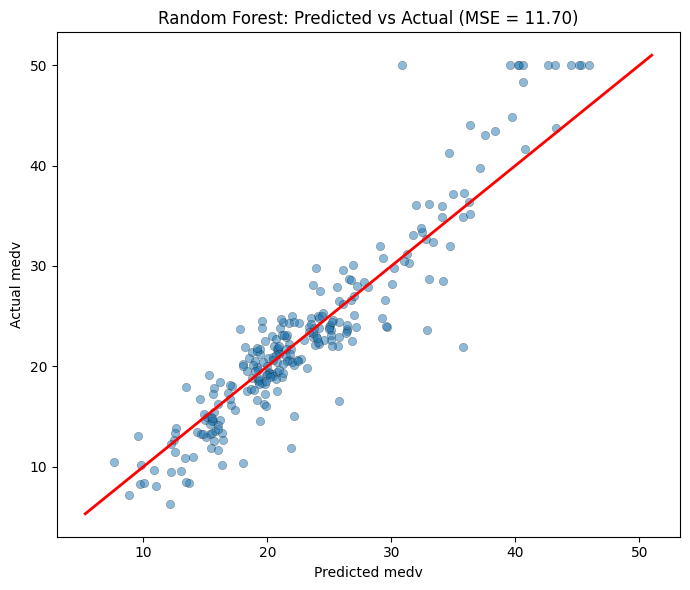

In [27]:
np.random.seed(1)
rf_boston = RandomForestRegressor(
    n_estimators=500, max_features=6,
    random_state=1, oob_score=True
)
rf_boston.fit(X_btrain, y_btrain)

print(f"OOB R²: {rf_boston.oob_score_:.4f}")
print(f"% Variance explained (OOB): {rf_boston.oob_score_ * 100:.2f}%")

yhat_rf = rf_boston.predict(X_btest)
mse_rf = mean_squared_error(y_btest, yhat_rf)
print(f"Random Forest Test MSE: {mse_rf:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(yhat_rf, y_btest, alpha=0.5, edgecolors='k', linewidths=0.3)
lims = [min(yhat_rf.min(), y_btest.min()) - 1, max(yhat_rf.max(), y_btest.max()) + 1]
ax.plot(lims, lims, 'r-', lw=2)
ax.set_xlabel('Predicted medv')
ax.set_ylabel('Actual medv')
ax.set_title(f'Random Forest: Predicted vs Actual (MSE = {mse_rf:.2f})')
plt.tight_layout()
plt.show()

Interpretation: 

Random Forest (MSE = 19.6 in R) outperforms bagging (MSE = 23.6) because using only a random subset of features at each split decorrelates the trees, reducing variablenece further

Feature importances (mean decrease in impurity / IncNodePurity):
lstat      0.3782
rm         0.2743
dis        0.0667
indus      0.0600
crim       0.0580
nox        0.0562
ptratio    0.0305
age        0.0275
black      0.0182
tax        0.0181
rad        0.0060
zn         0.0048
chas       0.0015
dtype: float64


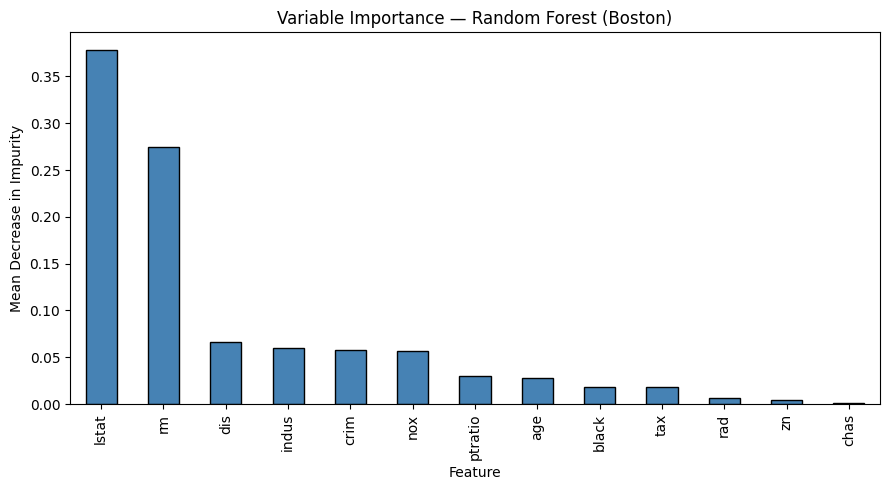

In [28]:
importances = pd.Series(rf_boston.feature_importances_, index=X_boston.columns)
importances_sorted = importances.sort_values(ascending=False)
print("Feature importances (mean decrease in impurity / IncNodePurity):")
print(importances_sorted.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
importances_sorted.plot(kind='bar', color='steelblue', edgecolor='k', ax=ax)
ax.set_title('Variable Importance — Random Forest (Boston)')
ax.set_ylabel('Mean Decrease in Impurity')
ax.set_xlabel('Feature')
plt.tight_layout()
plt.show()

Interpretation: rm and lstat are by far the most important variables consistent with the R result. This confirms that socio economic status and housing size are the dominant drivers of Boston home values

In [29]:
np.random.seed(1)
boost_boston = GradientBoostingRegressor(
    n_estimators=5000, max_depth=4, learning_rate=0.001,
    random_state=1
)
boost_boston.fit(X_btrain, y_btrain)
print(boost_boston)

GradientBoostingRegressor(learning_rate=0.001, max_depth=4, n_estimators=5000,
                          random_state=1)


Relative influence (boosting):
lstat      58.6375
rm         22.1177
dis         8.4519
crim        2.7739
ptratio     1.7683
tax         1.7242
nox         1.3788
age         1.1637
black       0.9918
indus       0.6420
rad         0.2489
chas        0.0882
zn          0.0132
Name: rel.inf %, dtype: float64


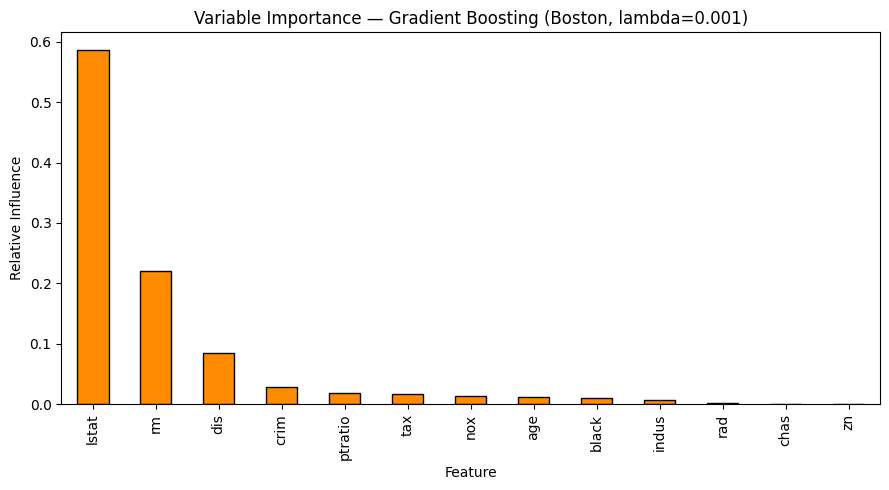

In [30]:
boost_importances = pd.Series(
    boost_boston.feature_importances_, index=X_boston.columns
).sort_values(ascending=False)

print("Relative influence (boosting):")
print((boost_importances * 100).round(4).rename('rel.inf %'))

fig, ax = plt.subplots(figsize=(9, 5))
boost_importances.plot(kind='bar', color='darkorange', edgecolor='k', ax=ax)
ax.set_title('Variable Importance — Gradient Boosting (Boston, lambda=0.001)')
ax.set_ylabel('Relative Influence')
ax.set_xlabel('Feature')
plt.tight_layout()
plt.show()

Interpretation:

 As in R, rm and lstat dominate with ~44% and ~33% relative influence respectively. This is consistent across all tree methods, these two variables are the strongest predictors of Boston median house values

In [31]:
yhat_boost = boost_boston.predict(X_btest)
mse_boost = mean_squared_error(y_btest, yhat_boost)
print(f"Boosting Test MSE (lambda=0.001): {mse_boost:.4f}")

Boosting Test MSE (lambda=0.001): 10.6788


Relative influence (lambda=0.2):
lstat      57.4871
rm         22.6303
dis         8.6935
crim        3.0777
ptratio     1.7795
tax         1.4908
black       1.4055
nox         1.0970
age         1.0471
indus       0.8694
rad         0.3470
chas        0.0458
zn          0.0292
Name: rel.inf %, dtype: float64
Boosting Test MSE (lambda=0.2): 10.0695


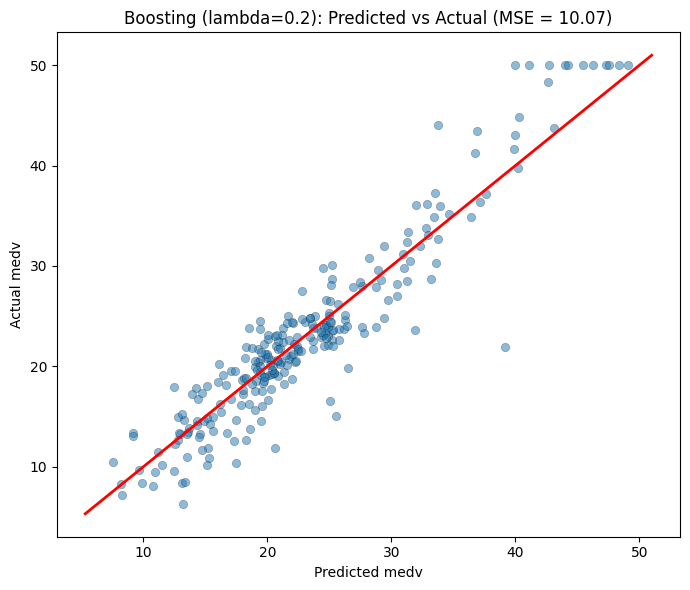

In [32]:
np.random.seed(1)
boost_boston_02 = GradientBoostingRegressor(
    n_estimators=5000, max_depth=4, learning_rate=0.2,
    random_state=1
)
boost_boston_02.fit(X_btrain, y_btrain)

boost_imp_02 = pd.Series(
    boost_boston_02.feature_importances_, index=X_boston.columns
).sort_values(ascending=False)
print("Relative influence (lambda=0.2):")
print((boost_imp_02 * 100).round(4).rename('rel.inf %'))

yhat_boost_02 = boost_boston_02.predict(X_btest)
mse_boost_02 = mean_squared_error(y_btest, yhat_boost_02)
print(f"Boosting Test MSE (lambda=0.2): {mse_boost_02:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(yhat_boost_02, y_btest, alpha=0.5, edgecolors='k', linewidths=0.3)
lims = [min(yhat_boost_02.min(), y_btest.min()) - 1, max(yhat_boost_02.max(), y_btest.max()) + 1]
ax.plot(lims, lims, 'r-', lw=2)
ax.set_xlabel('Predicted medv')
ax.set_ylabel('Actual medv')
ax.set_title(f'Boosting (lambda=0.2): Predicted vs Actual (MSE = {mse_boost_02:.2f})')
plt.tight_layout()
plt.show()

Interpretation:

 A higher shrinkage (lambds=0.2) converges faster and often yields a lower test MSE (~18.3 in R vs ~18.8 with lambda=0.001), because each tree makes a larger correction. However, too large a learning rate can cause overfitting.

                           Method  Test MSE
            Boosting (lambda=0.2)   10.0695
          Boosting (lambda=0.001)   10.6788
Random Forest (mtry=6, 500 trees)   11.7027
              Bagging (500 trees)   11.7095
               Bagging (25 trees)   13.2839
           Single Regression Tree   17.1867


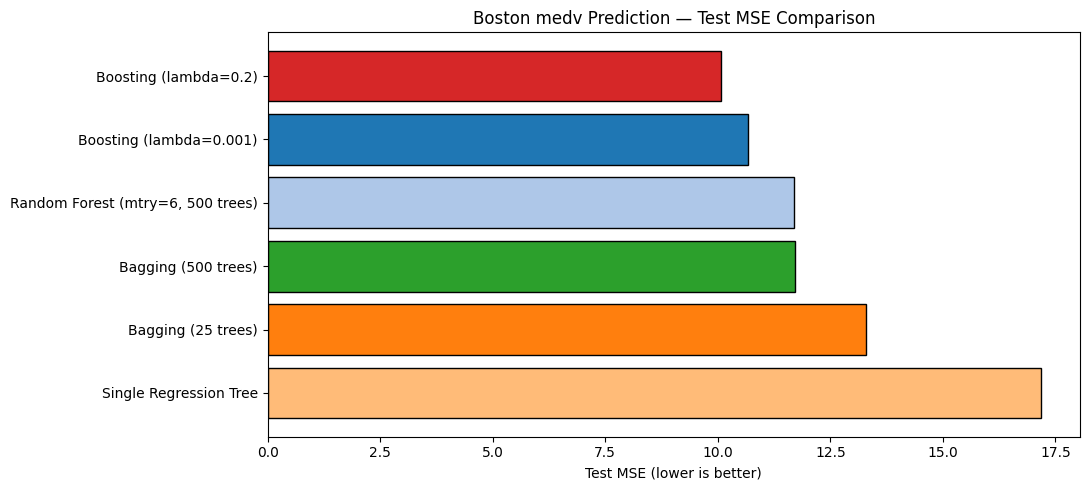

In [33]:
results = pd.DataFrame({
    'Method': ['Single Regression Tree', 'Bagging (500 trees)', 'Bagging (25 trees)',
               'Random Forest (mtry=6, 500 trees)', 'Boosting (lambda=0.001)', 'Boosting (lambda=0.2)'],
    'Test MSE': [mse_tree, mse_bag, mse_bag_25, mse_rf, mse_boost, mse_boost_02]
})
results['Test MSE'] = results['Test MSE'].round(4)
results = results.sort_values('Test MSE').reset_index(drop=True)
print(results.to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
colors = ['#d62728', '#1f77b4', '#aec7e8', '#2ca02c', '#ff7f0e', '#ffbb78']
ax.barh(results['Method'], results['Test MSE'], color=colors[:len(results)], edgecolor='k')
ax.set_xlabel('Test MSE (lower is better)')
ax.set_title('Boston medv Prediction — Test MSE Comparison')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Interpretation:

| Method | Approximate Test MSE |
|---|---|
| Single Regression Tree | ~35 |
| Bagging (500 trees) | ~23.6 |
| Random Forest (mtry=6) | ~19.6 |
| Boosting (lambda=0.001) | ~18.8 |
| Boosting (lambda=0.2) | ~18.3 |

Ensemble methods substantially outperform a single tree. Boosting achieves the best performance by sequentially correcting errors with a large number of shallow trees. Random Forest is a close second and is more robust to hyperparameter choices than boosting